[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_05/MFM_ch5_garch_simulation/MFM_ch5_garch_simulation.ipynb)

# MFM_ch5_garch_simulation

Why Generalised AutoRegressive Conditional Heteroskedasticity (GARCH) produces volatility clustering: a simulated GARCH(1,1) path next to i.i.d. Normal returns with the same unconditional variance, and the kurtosis and autocorrelation of squared returns on a long simulated path.

*Modelling Financial Markets (MFM), Chapter 5: Conditional Volatility, GARCH Models. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Bucharest University of Economic Studies (ASE) Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (comma-separated values (CSV), charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_5'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261016T123500-540761


In [ ]:
# the arch package (Kevin Sheppard) is not preinstalled on Colab
try:
    import arch
except ImportError:
    import subprocess
    import sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'], check=True)

In [ ]:
import os
import re
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats, optimize
from scipy.signal import lfilter
from scipy.special import gammaln
from arch import arch_model
from arch.univariate import ARCHInMean, ConstantMean, GARCH, FIGARCH, StudentsT, ZeroMean
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
# font sizes for slides (charts are 9-11 inches wide and shown at 8-14 cm)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 13
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11.5
plt.rcParams['ytick.labelsize'] = 11.5
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.4
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 11

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'
COL = {'sp500': MainBlue, 'bet': IDAred, 'bettr': Orange, 'btc': Amber, 'eurron': Forest, 'gold': Purple}

SEED = 42
TABLE_DIR = '.'
NUM = {}


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def acf(x, nlags):
    x = np.asarray(x) - np.mean(x)
    d = np.sum(x ** 2)
    return np.array([np.sum(x[k:] * x[:-k]) / d for k in range(1, nlags + 1)])

## Data

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, label, group, start date)
MARKETS = {
    'sp500':  ('GSPC.INDX',      'S&P 500',                 'Equity', '2000-01-01'),
    'bet':    ('BET',            'BET',                     'Equity', '2000-01-01'),
    'bettr':  ('BETTR.INDX',     'BET-TR',                  'Equity', '2014-09-23'),
    'btc':    ('BTC-USD.CC',     'Bitcoin',                 'Crypto', '2014-09-17'),
    'eurron': ('REF:EUR',        'EUR/RON (BNR reference)', 'FX',     '2005-07-01'),
    'gold':   ('XAUUSD.FOREX',   'Gold (XAU/USD)',          'Commodity', '2000-01-01'),
}
LABELS = {k: v[1] for k, v in MARKETS.items()}

_CACHE = {}


def read_market(symbol):
    """Daily price table of one symbol (local copy of the course data, or GitHub)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official RON reference rate (annual BNR XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END):
    """Daily closing price, cleaned with the chapter conventions."""
    symbol, _, group, start0 = MARKETS[name]
    start = start or start0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    d = read_market(symbol).loc[start:end]
    d = d[d['close'] > 0].dropna(subset=['close'])
    if group != 'Crypto':
        d = d[d.index.dayofweek < 5]          # no weekend quotes
        d = d[~artificial_fill(d)]            # non-trading days filled with the previous price
    return d['close'].rename(name)


def artificial_fill(d):
    """Rows that repeat the previous close and show no trading: an artificial non-trading-day fill.

    A repeated close is a fill only if the row itself shows no trading: zero volume (for files that report
    volume), no intraday range (open = high = low = close) or a copy of the previous row in every field. A
    repeated close on a day with volume and an intraday range is a genuine unchanged close (a zero return)
    and is kept. Files with closes only (the BET) give no such evidence, so every row is kept.
    """
    repeat = d['close'].diff() == 0
    no_trade = pd.Series(False, index=d.index)
    if 'volume' in d and (d['volume'] > 0).mean() > 0.5:
        no_trade |= d['volume'].fillna(0) <= 0
    if {'open', 'high', 'low'} <= set(d.columns):
        no_trade |= (d['open'] == d['high']) & (d['high'] == d['low']) & (d['low'] == d['close'])
        fields = [c for c in ['open', 'high', 'low', 'close', 'volume'] if c in d]
        no_trade |= (d[fields] == d[fields].shift()).all(axis=1)
    return repeat & no_trade


def pct_returns(name, start=None, end=END):
    """Daily log returns in percent, on the series' own calendar."""
    return (100 * np.log(load_close(name, start, end)).diff().dropna()).rename(name)


def periods_per_year(r):
    """Average number of observations per calendar year (actual frequency of the series)."""
    years = (r.index[-1] - r.index[0]).days / 365.25
    return len(r) / years


def load_vix(start='2000-01-01', end=END):
    """The VIX index (30-day implied volatility of the S&P 500, annualised percent)."""
    s = read_market('VIX.INDX')['close'].loc[start:end]
    return s[s.index.dayofweek < 5].rename('vix')


rets = {k: pct_returns(k) for k in MARKETS}
PPY = {k: periods_per_year(rets[k]) for k in MARKETS}
ORDER = list(MARKETS)
MAIN = ['sp500', 'bet', 'btc', 'eurron', 'gold']
for k in ORDER:
    print(f'{LABELS[k]:26s}', rets[k].index[0].date(), '->', rets[k].index[-1].date(), len(rets[k]), 'obs',
          round(PPY[k], 1), 'obs/year')

S&P 500                    2000-01-04 -> 2026-09-18 6714 obs 251.4 obs/year
BET                        2000-01-06 -> 2026-09-18 6670 obs 249.8 obs/year
BET-TR                     2014-09-24 -> 2026-09-18 2992 obs 249.7 obs/year
Bitcoin                    2014-09-18 -> 2026-09-18 4384 obs 365.3 obs/year
EUR/RON (BNR reference)    2005-07-05 -> 2026-09-18 5352 obs 252.4 obs/year
Gold (XAU/USD)             2000-01-04 -> 2026-09-18 6922 obs 259.2 obs/year


## GARCH tools

In [ ]:
VOL_SPEC = {'GARCH': dict(vol='GARCH', p=1, o=0, q=1),
            'GJR': dict(vol='GARCH', p=1, o=1, q=1),
            'EGARCH': dict(vol='EGARCH', p=1, o=1, q=1)}
DISTS = {'normal': 'Normal', 't': 'Student-t', 'skewt': 'Skewed-t', 'ged': 'GED'}


class Fit:
    """Result of one fit, in the units of the original series (returns in %)."""

    def __init__(self, res, c, r, vol):
        self.res, self.c, self.r, self.vol = res, c, r, vol
        p = res.params.copy()
        p['mu'] = p['mu'] / c
        if vol == 'EGARCH':
            p['omega'] = p['omega'] - (1 - p['beta[1]']) * np.log(c ** 2)
        else:
            p['omega'] = p['omega'] / c ** 2
        self.params = p
        # robust (Bollerslev-Wooldridge) covariance mapped to the original units with the Jacobian
        # of the transformation: mu/c, omega/c^2 (GARCH, GJR) or omega - (1 - beta) ln c^2 (EGARCH)
        names = list(res.params.index)
        J = np.eye(len(names))
        J[names.index('mu'), names.index('mu')] = 1 / c
        if vol == 'EGARCH':
            J[names.index('omega'), names.index('beta[1]')] = np.log(c ** 2)
        else:
            J[names.index('omega'), names.index('omega')] = 1 / c ** 2
        self.cov = pd.DataFrame(J @ res.param_cov.values @ J.T, index=names, columns=names)
        self.se = pd.Series(np.sqrt(np.diag(self.cov.values)), index=names)
        self.tvalues = p[names] / self.se
        self.pvalues = pd.Series(2 * stats.norm.sf(np.abs(self.tvalues.values)), index=names)
        n = res.nobs
        self.nobs = n
        self.loglik = res.loglikelihood + n * np.log(c)
        k = len(p)
        self.aic = -2 * self.loglik + 2 * k
        self.bic = -2 * self.loglik + k * np.log(n)
        self.sigma = res.conditional_volatility / c
        self.z = res.std_resid
        self.eps = res.resid / c                   # unstandardised residuals, in the units of the original series
        self.converged = res.convergence_flag == 0

    @property
    def persistence(self):
        p = self.params
        if self.vol == 'EGARCH':
            return p['beta[1]']
        g = p.get('gamma[1]', 0.0)
        return p['alpha[1]'] + p['beta[1]'] + g * self.neg_share()

    def neg_share(self):
        """E[z^2 1(z < 0)] for the innovation distribution (0.5 if symmetric); enters the GJR persistence."""
        d = self.res.model.distribution
        if d.name.startswith('Standardized Skew'):
            from scipy import integrate
            par = self.res.params[d.parameter_names()].values
            pdf = lambda x: float(np.exp(d.loglikelihood(par, np.array([x]), np.array([1.0]), individual=True))[0])
            return float(integrate.quad(lambda x: x ** 2 * pdf(x), -np.inf, 0, limit=200)[0])
        return 0.5

    def uncond_var(self):
        p = self.params
        if self.vol == 'EGARCH':
            return np.nan
        return p['omega'] / (1 - self.persistence)

    def forecast_var(self, horizon):
        """Daily variance forecasts for t+1, ..., t+h, in %^2."""
        f = self.res.forecast(horizon=horizon, reindex=False, method='analytic' if self.vol != 'EGARCH' else 'simulation',
                              simulations=2000)
        return f.variance.iloc[-1].values / self.c ** 2


def scale_for(r):
    """Rescaling factor (a power of 10) that makes the standard deviation of order 1."""
    s = r.std()
    return 10.0 if s < 0.5 else 1.0


def fit_garch(r, vol='GARCH', dist='t', mean='Constant', last_obs=None, c=None):
    c = scale_for(r) if c is None else c
    am = arch_model(c * r, mean=mean, dist=dist, **VOL_SPEC[vol])
    if not (vol == 'EGARCH' and dist == 't' and mean == 'Constant'):
        res = am.fit(disp='off', last_obs=last_obs, options={'maxiter': 1000})
        return Fit(res, c, r, vol)

    import warnings
    # Numerical recovery uses the same model, scale and estimation sample.
    with warnings.catch_warnings(record=True) as initial_warnings:
        warnings.simplefilter('always')
        res = am.fit(disp='off', last_obs=last_obs, options={'maxiter': 1000})
    fit_indices = tuple(am._fit_indices)
    fit_y = np.asarray(am._fit_y).copy()
    backcast = np.asarray(am._backcast).copy()
    variance_bounds = np.asarray(am._var_bounds).copy()
    residuals0 = np.asarray(am.resids(am.starting_values()))
    volatility_start = am.volatility.starting_values(residuals0)
    sigma2 = np.empty_like(residuals0)
    am.volatility.compute_variance(volatility_start, residuals0, sigma2,
                                   am._backcast, variance_bounds)
    bounds = (list(am.bounds()) + list(am.volatility.bounds(residuals0))
              + list(am.distribution.bounds(residuals0 / np.sqrt(sigma2))))
    groups = [(am.constraints(), slice(0, 1)),
              (am.volatility.constraints(), slice(1, 5)),
              (am.distribution.constraints(), slice(5, 6))]
    names = list(res.params.index)
    if names != ['mu', 'omega', 'alpha[1]', 'gamma[1]', 'beta[1]', 'nu']:
        raise RuntimeError('Unsupported EGARCH parameter order for numerical recovery.')
    if len(bounds) != 6 or not np.isfinite(fit_y).all():
        raise RuntimeError('Invalid EGARCH estimation sample or parameter bounds.')

    def feasible(p, tolerance=1e-8):
        if not np.isfinite(p).all():
            return False
        if any(value < lo - tolerance or value > hi + tolerance
               for value, (lo, hi) in zip(p, bounds)):
            return False
        return all(np.all(A @ p[sl] - b >= -tolerance)
                   for (A, b), sl in groups)

    def assess(result, caught):
        p = np.asarray(result.params)
        opt = result.optimization_result
        reasons = []
        if result.convergence_flag != 0 or not bool(opt.success):
            reasons.append('optimizer did not converge')
        if any(type(w.message).__name__ in ('ConvergenceWarning', 'StartingValueWarning')
               for w in caught):
            reasons.append('optimizer or rejected-start warning')
        if not feasible(p):
            reasons.append('nonfinite or inadmissible parameters')
        objective = float(opt.fun)
        if (not np.isfinite(objective) or not np.isfinite(result.loglikelihood)
                or not np.isclose(objective, -result.loglikelihood, rtol=1e-10, atol=1e-8)):
            reasons.append('inconsistent or nonfinite objective')
        start, stop = fit_indices
        sig = np.asarray(result.conditional_volatility)[start:stop]
        z = np.asarray(result.std_resid)[start:stop]
        if len(sig) != len(fit_y) or not (np.isfinite(sig).all() and np.all(sig > 0)
                                         and np.isfinite(z).all()):
            reasons.append('invalid fitted conditional variance or residuals')
        if (tuple(am._fit_indices) != fit_indices
                or not np.array_equal(np.asarray(am._fit_y), fit_y)
                or not np.array_equal(np.asarray(am._backcast), backcast)
                or not np.array_equal(np.asarray(am._var_bounds), variance_bounds)):
            raise RuntimeError('EGARCH recovery changed sample, backcast or variance bounds.')
        if feasible(p):
            common_objective = float(am._loglikelihood(
                p, np.empty_like(fit_y), am._backcast, variance_bounds))
            if not np.isclose(objective, common_objective, rtol=1e-10, atol=1e-8):
                reasons.append('objective differs from the frozen original problem')
        else:
            common_objective = float('nan')
        return {'flag': int(result.convergence_flag), 'success': bool(opt.success),
                'message': str(opt.message), 'objective': objective,
                'common_objective': common_objective, 'admissible': not reasons,
                'reasons': reasons, 'warnings': [str(w.message) for w in caught]}

    default_record = assess(res, initial_warnings)
    if default_record['admissible']:
        for warning in initial_warnings:
            warnings.warn_explicit(warning.message, warning.category, warning.filename, warning.lineno)
        return Fit(res, c, r, vol)

    starts = [(0.90, 0.10, 0.0, 8.0), (0.95, 0.15, 0.0, 8.0),
              (0.90, 0.30, -0.05, 4.0), (0.98, 0.10, 0.05, 12.0),
              (0.80, 0.20, 0.0, 6.0)]
    attempts, valid = [], []
    for number, (beta, alpha, gamma, nu) in enumerate(starts):
        omega = float(np.clip((1 - beta) * np.log(np.var(fit_y)), *bounds[1]))
        start = np.array([fit_y.mean(), omega, alpha, gamma, beta, nu])
        if not feasible(start, tolerance=0):
            raise RuntimeError('Generic EGARCH starting value is outside the original constraints.')
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                candidate = am.fit(disp='off', last_obs=last_obs,
                                   starting_values=start, options={'maxiter': 1000})
            record = assess(candidate, caught)
            if record['admissible']:
                valid.append((record['objective'], number, candidate))
        except (ValueError, FloatingPointError, np.linalg.LinAlgError) as exc:
            record = {'admissible': False, 'error': type(exc).__name__ + ': ' + str(exc)}
        record.update(start_number=number, starting_values=start.tolist())
        attempts.append(record)
    if not valid:
        raise RuntimeError('EGARCH default and all recovery attempts failed: ' + str(attempts))
    _, selected, result = min(valid, key=lambda entry: (entry[0], entry[1]))
    fit = Fit(result, c, r, vol)
    fit.recovery = {'default': default_record, 'attempts': attempts,
                    'selected_start': selected, 'scale': c,
                    'fit_indices': fit_indices, 'estimation_sample_size': len(fit_y),
                    'interpretation': 'Same-model local optimizer recovery, not proof of a global optimum.'}
    print('EGARCH numerical recovery: default flag', default_record['flag'],
          '; selected generic start', selected, '; negative log-likelihood', result.optimization_result.fun)
    return fit


def half_life(persistence):
    """Number of days after which half of a variance shock has gone."""
    return np.log(0.5) / np.log(persistence) if 0 < persistence < 1 else np.inf


def news_impact(fit, eps, sigma2_bar=None):
    """sigma^2_t as a function of the shock eps_{t-1}, with sigma^2_{t-1} fixed at the sample variance."""
    p = fit.params
    s2 = fit.r.var() if sigma2_bar is None else sigma2_bar
    if fit.vol == 'EGARCH':
        z = eps / np.sqrt(s2)
        return np.exp(p['omega'] + p['alpha[1]'] * (np.abs(z) - np.sqrt(2 / np.pi)) + p['gamma[1]'] * z
                      + p['beta[1]'] * np.log(s2))
    g = p.get('gamma[1]', 0.0)
    return p['omega'] + (p['alpha[1]'] + g * (eps < 0)) * eps ** 2 + p['beta[1]'] * s2


def sign_bias_test(z, eps):
    """Engle-Ng (1993, eq. 18): z_t^2 on S-_{t-1}, S-_{t-1} eps_{t-1}, S+_{t-1} eps_{t-1}, with eps_{t-1} the
    UNSTANDARDISED residual and z_t the standardised residual; t statistics and the joint test T R^2 ~ chi2(3)."""
    d = pd.concat([pd.Series(z), pd.Series(eps)], axis=1, keys=['z', 'e']).dropna()
    z, e = d['z'].values, d['e'].values
    y = z[1:] ** 2
    el = e[:-1]
    sneg = (el < 0).astype(float)
    X = np.column_stack([np.ones_like(el), sneg, sneg * el, (1 - sneg) * el])
    ols = sm.OLS(y, X).fit()
    joint = len(y) * ols.rsquared
    return {'sign_t': ols.tvalues[1], 'neg_size_t': ols.tvalues[2], 'pos_size_t': ols.tvalues[3],
            'joint': joint, 'joint_p': 1 - stats.chi2.cdf(joint, 3)}


def ljung_box(x, lags=10):
    from statsmodels.stats.diagnostic import acorr_ljungbox
    lb = acorr_ljungbox(pd.Series(np.asarray(x)).dropna(), lags=[lags])
    return float(lb['lb_stat'].iloc[0]), float(lb['lb_pvalue'].iloc[0])


def arch_lm(x, lags=5):
    from statsmodels.stats.diagnostic import het_arch
    lm, lmp, _, _ = het_arch(pd.Series(np.asarray(x)).dropna(), nlags=lags)
    return float(lm), float(lmp)


def ewma_variance(r, lam=0.94, init=250):
    """EWMA forecast for day t+1 (aligned at t+1): s2_{t+1} = lam s2_t + (1 - lam) r_t^2."""
    x = r.values
    s2 = np.empty(len(x) + 1)
    s2[0] = np.mean(x[:init] ** 2)
    for t in range(len(x)):
        s2[t + 1] = lam * s2[t] + (1 - lam) * x[t] ** 2
    return pd.Series(s2[1:-1], index=r.index[1:])


def qlike(proxy, h):
    """QLIKE loss (Patton, 2011), the form used for comparisons: proxy/h + ln h."""
    return proxy / h + np.log(h)


def mz_regression(proxy, h, lags=5):
    """Mincer-Zarnowitz: proxy = a + b h + u, HAC errors; Wald test of a = 0, b = 1."""
    X = sm.add_constant(np.asarray(h))
    ols = sm.OLS(np.asarray(proxy), X).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    w = ols.wald_test((np.eye(2), np.array([0.0, 1.0])), scalar=True)
    return {'a': ols.params[0], 'b': ols.params[1], 'a_se': ols.bse[0], 'b_se': ols.bse[1],
            'r2': ols.rsquared, 'wald': float(w.statistic), 'wald_p': float(w.pvalue)}


def dm_test(loss_a, loss_b, lags=5):
    """Diebold-Mariano: d = L_a - L_b; HAC t statistic for the mean of d (negative: A better)."""
    d = np.asarray(loss_a) - np.asarray(loss_b)
    ols = sm.OLS(d, np.ones_like(d)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    t = float(ols.tvalues[0])
    return {'mean_diff': float(d.mean()), 't': t, 'p': 2 * (1 - stats.norm.cdf(abs(t)))}

## Analysis

In [ ]:
def fig_simulation():
    n = 2000
    rng = np.random.default_rng(SEED)
    om, al, be = 0.02, 0.10, 0.88
    s2 = np.empty(n)
    x = np.empty(n)
    s2[0] = om / (1 - al - be)
    z = rng.standard_normal(n)
    for t in range(n):
        if t > 0:
            s2[t] = om + al * x[t - 1] ** 2 + be * s2[t - 1]
        x[t] = np.sqrt(s2[t]) * z[t]
    iid = np.sqrt(om / (1 - al - be)) * rng.standard_normal(n)
    fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, sharey=True)
    axes[0].plot(iid, color=Teal, lw=0.5, label='i.i.d. Normal, same unconditional variance')
    axes[1].plot(x, color=MainBlue, lw=0.5, label=r'GARCH(1,1): $\omega=0.02$, $\alpha=0.10$, $\beta=0.88$')
    axes[1].plot(2 * np.sqrt(s2), color=IDAred, lw=0.8, label=r'$\pm 2\sigma_t$')
    axes[1].plot(-2 * np.sqrt(s2), color=IDAred, lw=0.8)
    for ax in axes:
        ax.set_ylabel('Return (%)')
    axes[1].set_xlabel('Day')
    fig.tight_layout()
    h = [l for ax in axes for l in ax.get_lines() if not l.get_label().startswith('_')]
    fig.legend(h, [l.get_label() for l in h], loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
    save_fig('ch5_simulation')
    # statistics on a long path (one million days), not on the 2000 days of the chart
    N = 1_000_000
    zl = rng.standard_normal(N)
    xl = np.empty(N)
    s = om / (1 - al - be)
    for t in range(N):
        xl[t] = np.sqrt(s) * zl[t]
        s = om + al * xl[t] ** 2 + be * s
    NUM['sim'] = {'kurt_garch': float(stats.kurtosis(xl)), 'acf1_x2': float(acf(xl ** 2, 1)[0]),
                  'kurt_theory': float(3 * (1 - (al + be) ** 2) / (1 - (al + be) ** 2 - 2 * al ** 2) - 3),
                  'uvar': om / (1 - al - be)}

## Run

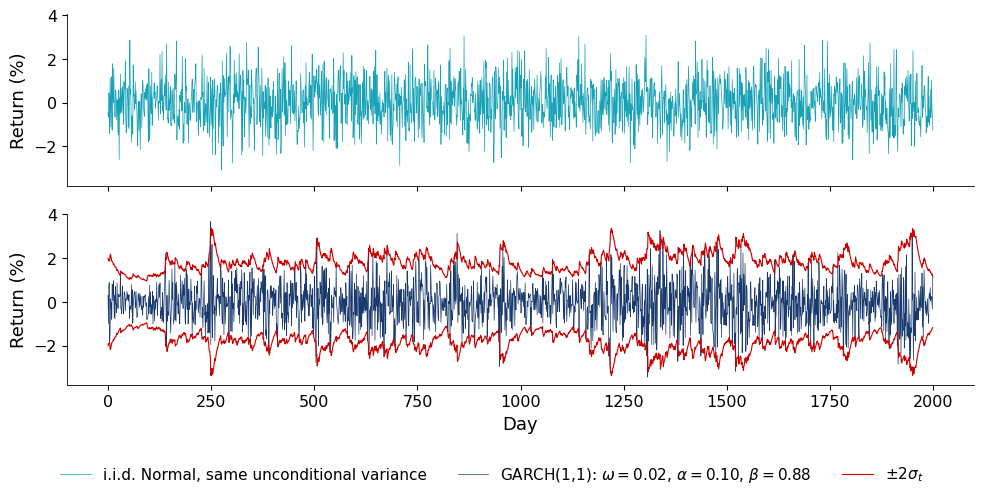

   saved ch5_simulation


{'kurt_garch': 2.4694857348568133, 'acf1_x2': 0.26051574156251517, 'kurt_theory': 3.061224489795907, 'uvar': 0.9999999999999991}


In [ ]:
fig_simulation()
print(NUM['sim'])

![ch5_simulation](./ch5_simulation.png)

Output: `ch5_simulation.pdf`